In [1]:
import jax
from jax import numpy as jnp

jax_rng = jax.random.key(seed=1)

num_samples_per_class = 1000
negative_samples = jax.random.multivariate_normal(
    key=jax_rng,
    mean=jnp.array([0.0, 3.0], dtype="float32"),
    cov=jnp.array(
        [
            [1.0, 0.5],
            [0.5, 1.0],
        ],
        dtype="float32",
    ),
    shape=(num_samples_per_class,),
)
positive_samples = jax.random.multivariate_normal(
    key=jax_rng,
    mean=jnp.array([3.0, 0.0], dtype="float32"),
    cov=jnp.array(
        [
            [1.0, 0.5],
            [0.5, 1.0],
        ],
        dtype="float32",
    ),
    shape=(num_samples_per_class,),
)
inputs = jnp.vstack((negative_samples, positive_samples), dtype="float32")
targets = jnp.vstack(
    (
        jnp.zeros(shape=(num_samples_per_class, 1)),
        jnp.ones(shape=(num_samples_per_class, 1)),
    ),
    dtype="float32",
)

print(f"{inputs.shape=}")
print(f"{targets.shape=}")

inputs.shape=(2000, 2)
targets.shape=(2000, 1)


In [2]:
input_dim, output_dim = 2, 1

W = jax.random.uniform(key=jax_rng, shape=(input_dim, output_dim), dtype="float32")
b = jnp.zeros(shape=(output_dim,), dtype="float32")

print(f"{W.shape=}")
print(f"{b.shape=}")

W.shape=(2, 1)
b.shape=(1,)


In [3]:
def dense(inputs, W, b):
    return jnp.matmul(inputs, W) + b

In [4]:
def mean_squared_error(prediction, actual):
    return jnp.mean(jnp.square(prediction - actual))

In [5]:
def compute_loss(state, inputs, targets):
    W, b = state
    predictions = dense(inputs, W, b)
    loss = mean_squared_error(predictions, targets)
    return loss

In [6]:
grad_fn = jax.value_and_grad(compute_loss)

In [7]:
learning_rate = 0.1


@jax.jit
def training_step(inputs, targets, W, b):
    loss, grad_of_loss_wrt_state = grad_fn((W, b), inputs, targets)
    grad_of_loss_wrt_W, grad_of_loss_wrt_b = grad_of_loss_wrt_state
    W = W - learning_rate * grad_of_loss_wrt_W
    b = b - learning_rate * grad_of_loss_wrt_b
    return loss, W, b

In [8]:
for step in range(40):
    loss, W, b = training_step(inputs, targets, W, b)
    print(f"Loss at step {step}: {loss:.4f}")

Loss at step 0: 1.9974
Loss at step 1: 0.2786
Loss at step 2: 0.1330
Loss at step 3: 0.1101
Loss at step 4: 0.1012
Loss at step 5: 0.0944
Loss at step 6: 0.0883
Loss at step 7: 0.0827
Loss at step 8: 0.0777
Loss at step 9: 0.0731
Loss at step 10: 0.0689
Loss at step 11: 0.0650
Loss at step 12: 0.0615
Loss at step 13: 0.0583
Loss at step 14: 0.0554
Loss at step 15: 0.0528
Loss at step 16: 0.0503
Loss at step 17: 0.0481
Loss at step 18: 0.0461
Loss at step 19: 0.0442
Loss at step 20: 0.0426
Loss at step 21: 0.0410
Loss at step 22: 0.0396
Loss at step 23: 0.0383
Loss at step 24: 0.0372
Loss at step 25: 0.0361
Loss at step 26: 0.0351
Loss at step 27: 0.0342
Loss at step 28: 0.0334
Loss at step 29: 0.0327
Loss at step 30: 0.0320
Loss at step 31: 0.0314
Loss at step 32: 0.0308
Loss at step 33: 0.0303
Loss at step 34: 0.0299
Loss at step 35: 0.0294
Loss at step 36: 0.0290
Loss at step 37: 0.0287
Loss at step 38: 0.0284
Loss at step 39: 0.0281


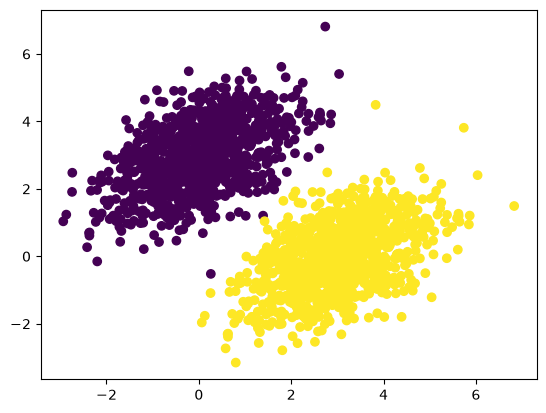

In [9]:
import matplotlib.pyplot as plt

preds = dense(inputs, W, b)
plt.scatter(inputs[:, 0], inputs[:, 1], c=preds[:, 0] > 0.5)
plt.show()